In [1]:
%pip install -U xgboost shap lime "pandas<2.3.0" scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 26.2 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 3.1.1
    Uninstalling pandas-3.1.1:
      Successfully uninstalled pandas-3.1.1


In [2]:
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Load the dataset as a DataFrame
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

# Dataset labels:
# 0 = Malignant
# 1 = Benign

class_names = ["Malignant", "Benign"]

# Separate training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (455, 30)
Testing shape: (114, 30)


### XGBoost Mathematical Formulation
The objective function to be optimized at iteration $t$ is:
$$ \mathcal{L}^{(t)} = \sum_{i=1}^n l(y_i, \hat{y}_i^{(t-1)} + f_t(x_i)) + \Omega(f_t) $$
where $l$ is a differentiable convex loss function, and $\Omega$ penalizes the complexity of the tree:
$$ \Omega(f_t) = \gamma T + \frac{1}{2}\lambda \sum_{j=1}^T w_j^2 $$
($T$ is the number of leaves, $w_j$ are the leaf weights).

In [3]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.0,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

# Predict class labels and probabilities
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

print("First five predictions:", y_pred[:5])
print("First five probability rows:\n", y_proba[:5])

First five predictions: [0 1 0 0 0]
First five probability rows:
 [[9.9873978e-01 1.2601959e-03]
 [9.1755390e-04 9.9908245e-01]
 [9.9648303e-01 3.5169553e-03]
 [5.9695935e-01 4.0304068e-01]
 [9.9866194e-01 1.3380571e-03]]


### Model Evaluation
Before explaining the model, let's evaluate its performance on the test set using standard classification metrics.

Classification Report:

              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



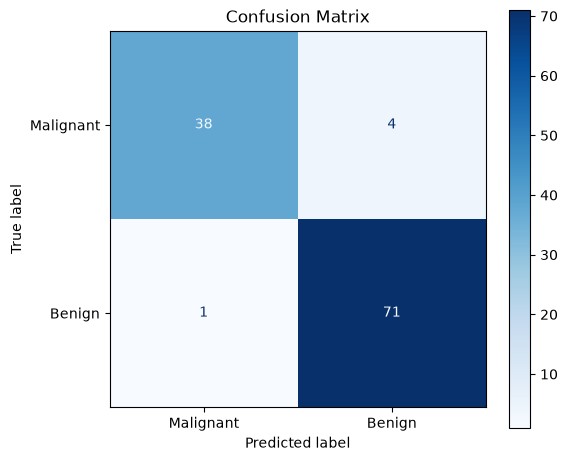

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Print the classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

### SHAP (SHapley Additive exPlanations)
SHAP assigns each feature an importance value representing its effect on the model prediction. The Shapley value $\phi_i$ for a feature $i$ is calculated as:
$$ \phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|! (|N| - |S| - 1)!}{|N|!} [f_{x}(S \cup \{i\}) - f_{x}(S)] $$
where $N$ is the set of all features, $S$ is a subset of features, and $f_{x}(S)$ is the model's expected output conditioned on subset $S$.

In [4]:
import shap
import matplotlib.pyplot as plt

# Select a small background dataset
background = X_train.sample(
    n=min(100, len(X_train)),
    random_state=42
)

# Create SHAP explainer
explainer = shap.TreeExplainer(
    model,
    data=background,
    model_output="probability"
)

# Explain a sample of test predictions
X_explain = X_test.iloc[:100]

shap_values = explainer(X_explain)

print("SHAP explanation shape:", shap_values.values.shape)

SHAP explanation shape: (100, 30)


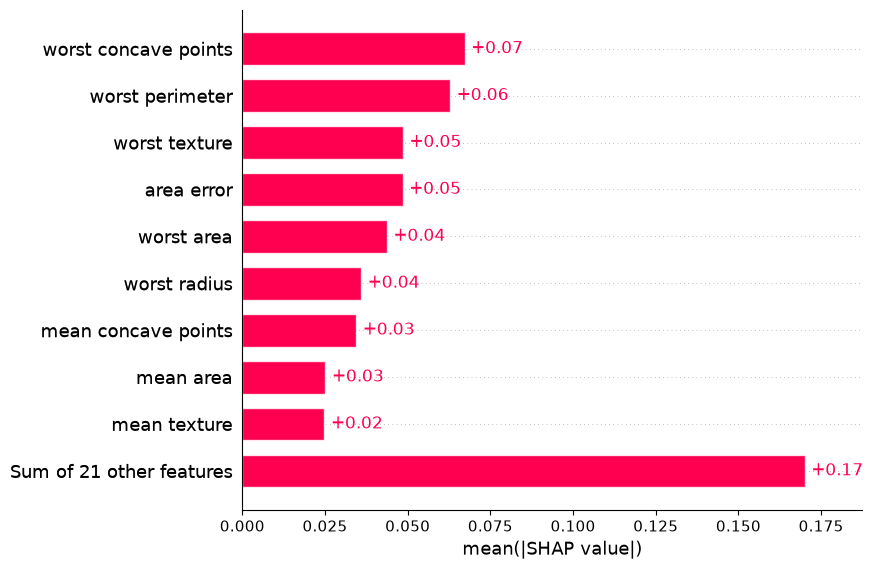

In [5]:
# Global feature importance
shap.plots.bar(shap_values)

plt.show()

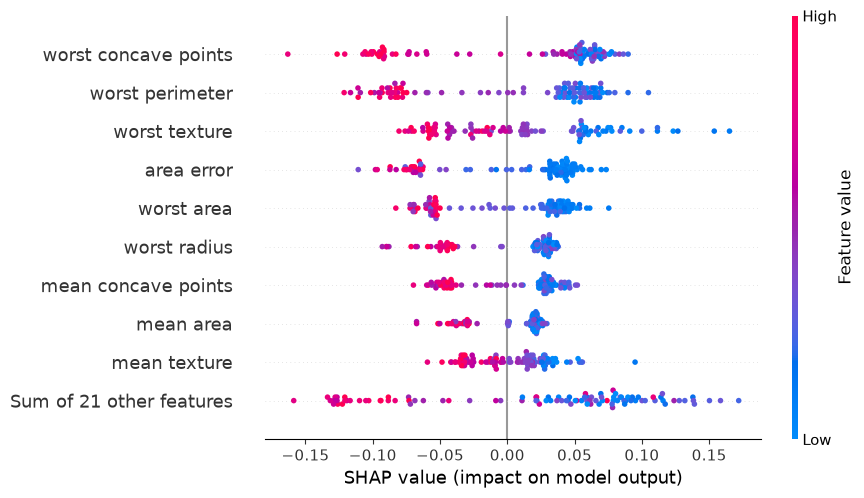

In [6]:
# Show feature importance and contribution direction
shap.plots.beeswarm(shap_values)

plt.show()

Actual: Malignant
Predicted: Malignant
Probabilities: [0.9987398 0.0012602]


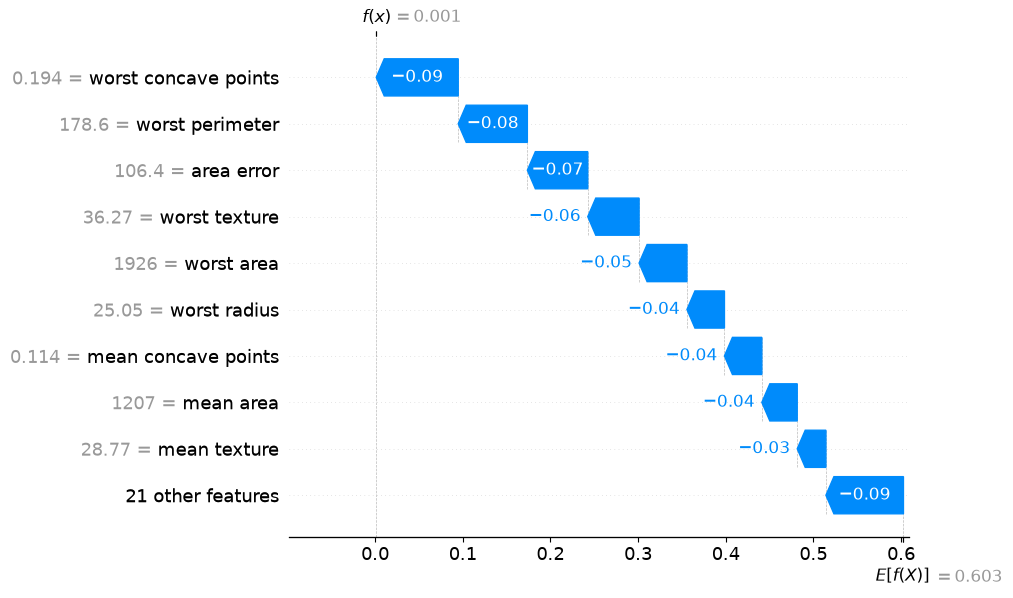

In [7]:
# Select one test observation
sample_index = 0

# Display its actual and predicted classes
actual_class = int(y_test.iloc[sample_index])
predicted_class = int(y_pred[sample_index])

print("Actual:", class_names[actual_class])
print("Predicted:", class_names[predicted_class])
print("Probabilities:", y_proba[sample_index])

# Explain the prediction
shap.plots.waterfall(shap_values[sample_index])

plt.show()

### LIME (Local Interpretable Model-agnostic Explanations)
LIME explains a prediction by approximating the complex model $f$ locally with an interpretable model $g$ (like a linear model). The objective is to minimize:
$$ \xi(x) = \arg\min_{g \in G} \mathcal{L}(f, g, \pi_x) + \Omega(g) $$
where $\mathcal{L}$ measures how unfaithful $g$ is to $f$ in the locality defined by $\pi_x$ (proximity measure around $x$), and $\Omega(g)$ is the complexity of the explanation model.

In [8]:
import numpy as np

from lime.lime_tabular import LimeTabularExplainer

# Create the LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=X_train.columns.tolist(),
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Select the same observation
sample = X_test.iloc[0].to_numpy()

# Generate local explanation
lime_explanation = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=model.predict_proba,
    labels=(0, 1),
    num_features=10,
    num_samples=5000
)

# Identify the predicted class
predicted_class = int(model.predict(X_test.iloc[[0]])[0])

# Print the explanation for that class
print("Predicted class:", class_names[predicted_class])

for feature, contribution in lime_explanation.as_list(
    label=predicted_class
):
    print(f"{feature}: {contribution:.4f}")

Predicted class: Malignant
worst concave points > 0.16: 0.2810
worst texture > 29.37: 0.1815
worst perimeter > 124.95: 0.1793
area error > 44.77: 0.1767
worst area > 1033.50: 0.1236
worst radius > 18.55: 0.1211
mean concave points > 0.07: 0.1078
mean area > 770.05: 0.1014
mean texture > 21.71: 0.0852
compactness error > 0.03: -0.0595


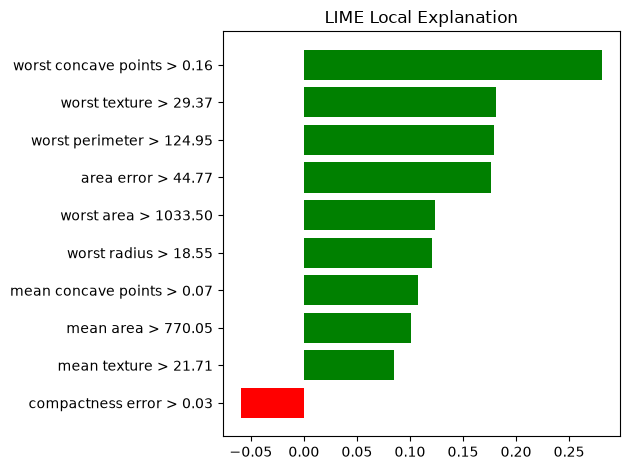

In [9]:
import matplotlib.pyplot as plt

fig = lime_explanation.as_pyplot_figure(
    label=predicted_class
)

plt.title("LIME Local Explanation")
plt.tight_layout()
plt.show()